# Projet AAA : émissions de CO2 et étiquette énergie des véhicules neufs

Pol BAILLEUL et Martin LEVALOIS, IMT Atlantique, 2026-2027

Rendu de l'étape 1 : analyse exploratoire des données et exploration non supervisée.

## 0. Objectif du projet
On travaille sur le fichier de l'ADEME qui recense les véhicules vendus en France. Chaque instance correspond à une version homologuée d'un véhicule, avec ses caractéristiques techniques et ses émissions.

C'est un problème d'apprentissage supervisé, qu'on peut voir de deux façons :
1. en régression : prédire les émissions de CO2 (`co2_g_km`, en g/km) ;
2. en classification : prédire la classe de l'étiquette énergie (A à G) ou le fait de dépasser 160 g/km (oui / non).

Le CO2 émis est directement lié à la quantité de carburant brûlée : les consommations (`conso_urb`, `conso_exurb`, `conso_mixte`) devraient donc donner quasiment la réponse (on le vérifie en section 7). On prévoit deux jeux d'entrées : le pipeline B, sans les consommations, qui est notre pipeline principal, et le pipeline A, avec, qui sert de référence haute.

On remarque également que la classe énergie se déduit directement du CO2 (il suffit de le comparer à des seuils). La classification est donc une version « découpée » de la régression, comme quand on classe les prix en catégories. On la traite quand même à part car le déséquilibre des classes et les mesures de performance ne sont pas les mêmes.

## Source des données
* Jeu de données sur data.gouv.fr : [Émissions de CO2 et de polluants des véhicules commercialisés en France](https://www.data.gouv.fr/fr/datasets/emissions-de-co2-et-de-polluants-des-vehicules-commercialises-en-france/)
* Une autre version existe sur data.ademe.fr ([ADEME - Car Labelling](https://data.ademe.fr/datasets/ademe-car-labelling)), on ne l'utilise pas.
* Les 3 247 dates renseignées dans la colonne `date_maj` vont de 2013 à 2014. Le fichier est copié sur [notre GitHub](https://github.com/Polbailleul/AAA-Project-Levalois-Bailleul) et chargé directement depuis ce dépôt.

## Travaux existants
On a regardé trois dépôts GitHub qui utilisent ces données (d'après leurs pages de présentation) :
* [cknogler/Vehicle-CO2-Emissions-Prediction](https://github.com/cknogler/Vehicle-CO2-Emissions-Prediction) : fichier ADEME 2013 réduit aux essences et diesels, puis dédoublonné en 5 700 configurations. Les entrées sont la masse, la puissance, le carburant, la boîte, le nombre de rapports et la carrosserie (pas de consommation). Avec un découpage 80/20, le gradient boosting obtient R² = 0,955 et une MAE de 7,5 g/km, contre 13,7 g/km pour les modèles linéaires (Ridge, Lasso). La masse et la puissance sont les attributs les plus importants.
* [aissatougueye06/ml-co2-prediction](https://github.com/aissatougueye06/ml-co2-prediction) : régressions linéaires simple et multiple (masse, puissance, boîte) sur les véhicules thermiques. Pour l'essence, l'erreur moyenne est de 15,5 g/km contre 42,9 g/km pour une prédiction constante. L'auteur signale aussi des fuites de données et beaucoup de versions répétées.
* [ziraax/Car_Labelling_Data_Analysis](https://github.com/ziraax/Car_Labelling_Data_Analysis) : analyse exploratoire et K-Means sur la masse et la consommation, sans résultats chiffrés.

On ne reprend pas leur code. On s'appuie sur le premier pour fixer un ordre de grandeur (une MAE vers 7 à 14 g/km sans les consommations) qu'on comparera à nos résultats à l'étape 2. Notre différence principale : au lieu de seulement dédoublonner, on découpe train/test par description commerciale (section 6) pour que les versions d'un même véhicule ne soient pas des deux côtés.


## 1. Imports
Tous les imports sont dans la cellule ci-dessous. On y ajoutera ceux des modèles pour les étapes suivantes.

In [168]:
# Tous les imports du notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pandas.plotting import scatter_matrix

import sklearn
from sklearn.model_selection import StratifiedShuffleSplit, GroupShuffleSplit, KFold, GroupKFold, cross_val_score
from sklearn.linear_model import Ridge
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (10, 5)
sns.set_theme(style="whitegrid", palette="muted")

## 2. Chargement des données
Le fichier brut a 30 colonnes, mais les 4 dernières (`Unnamed`) sont vides : chaque ligne se termine par un `;` en trop. La lecture en UTF-8 plante, on lit donc le fichier en `latin-1`, avec `;` comme séparateur et la virgule comme décimale. Quelques caractères restent mal décodés (par exemple « dÚc-13 » dans les dates), mais seulement dans des colonnes qu'on n'utilise pas.


In [169]:
# Copie du fichier ADEME hébergée sur le GitHub de l'équipe
GITHUB_RAW_URL = "https://raw.githubusercontent.com/Polbailleul/AAA-Project-Levalois-Bailleul/main/ademe_vehicules_co2.csv"

# Le fichier est encodé en latin-1 (le UTF-8 échoue) et séparé par des ";"
df_raw = pd.read_csv(GITHUB_RAW_URL, sep=";", encoding="latin-1", low_memory=False)
print(f"Fichier brut : {df_raw.shape[0]} instances x {df_raw.shape[1]} colonnes")
# Les rares dates de mise à jour renseignées (colonne écartée ensuite)
print("Dates de mise à jour renseignées :", df_raw["date_maj"].notna().sum(), "| exemples :", df_raw["date_maj"].dropna().unique()[:6].tolist())
display(df_raw.head(3))


Fichier brut : 55044 instances x 30 colonnes
Dates de mise à jour renseignées : 3247 | exemples : ['mars-14', 'mars-13', 'juin-13', 'dÚc-13', 'sept-13']


,lib_mrq,lib_mod_doss,lib_mod,dscom,cnit,tvv,cod_cbr,hybride,puiss_admin_98,puiss_max,...,masse_ordma_min,masse_ordma_max,champ_v9,date_maj,Carrosserie,gamme,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29
0,ALFA-ROMEO,159,159,159 1750 Tbi (200ch),M10ALFVP000G340,939AXN1B52C,ES,non,12,147,...,1505,1505,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
1,ALFA-ROMEO,159,159,159 1750 Tbi (200ch),M10ALFVP000H341,939BXN1B53C,ES,non,12,147,...,1555,1555,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN
2,ALFA-ROMEO,159,159,159 2.0 JTDm (136ch),M10ALFVP000E302,939AXR1B64,GO,non,7,100,...,1565,1565,715/2007*692/2008EURO5,mars-14,BERLINE,MOY-SUPER,NaN,NaN,NaN,NaN


## 3. Nettoyage et description du jeu
On écrit le nettoyage dans une fonction (`clean_ademe`) pour pouvoir le refaire facilement. Elle :
* supprime les colonnes vides et les doublons exacts ;
* renomme les colonnes avec des noms plus lisibles et convertit les virgules en points ;
* extrait la norme Euro (`EURO5`, `EURO6` ou `EEV`) à partir du champ brut ;
* supprime les instances sans CO2 ;
* fusionne la gamme `MOY-INFERIEURE` (56 instances) avec `MOY-INFER`, qui est la même gamme écrite autrement ;
* crée les cibles (`etiquette_energie`, `malus_eleve`) et un identifiant de groupe.

Pour l'étiquette, on reprend les seuils de l'étiquette CO2 française (arrêté du 10 avril 2003) : A jusqu'à 100 g/km, B de 101 à 120, C de 121 à 140, D de 141 à 160, E de 161 à 200, F de 201 à 250 et G au-delà. Le seuil de 160 g/km pour la cible binaire est un choix de notre part, ce n'est pas le barème actuel du malus.


In [170]:
# Noms de colonnes explicites
RENAME = {
    "lib_mrq": "marque", "lib_mod": "modele", "dscom": "description",
    "cod_cbr": "carburant", "hybride": "hybride",
    "puiss_admin_98": "puiss_admin_cv", "puiss_max": "puiss_max_kw",
    "typ_boite_nb_rapp": "boite_rapports",
    "conso_urb": "conso_urb", "conso_exurb": "conso_exurb", "conso_mixte": "conso_mixte",
    "co2": "co2_g_km", "co_typ_1": "co_g_km", "hc": "hc_g_km", "nox": "nox_g_km",
    "hcnox": "hcnox_g_km", "ptcl": "particules_g_km",
    "masse_ordma_min": "masse_min_kg", "masse_ordma_max": "masse_max_kg",
    "champ_v9": "norme_euro_brut", "Carrosserie": "carrosserie", "gamme": "gamme",
}
# Colonnes écartées d'emblée et raisons
DROPPED = {
    "lib_mod_doss": "nom de dossier du modèle, quasi identique à lib_mod",
    "cnit": "identifiant unique de chaque version (aucune information mécanique)",
    "tvv": "code type-variante-version (identifiant)",
    "date_maj": "date de mise à jour, presque toujours vide",
}
print("\nColonnes écartées :")
display(pd.Series(DROPPED, name="Raison").to_frame())

NUM_COLS = ["puiss_admin_cv", "puiss_max_kw", "masse_min_kg", "masse_max_kg",
            "conso_urb", "conso_exurb", "conso_mixte",
            "co_g_km", "hc_g_km", "nox_g_km", "hcnox_g_km", "particules_g_km", "co2_g_km"]
BINS = [0, 100, 120, 140, 160, 200, 250, np.inf]
LABELS = ["A", "B", "C", "D", "E", "F", "G"]


def clean_ademe(raw):
    """Nettoyage du fichier brut. Retourne le tableau propre et le journal du nombre d'instances."""
    log = [("Fichier brut", len(raw))]
    d = raw.loc[:, ~raw.columns.str.startswith("Unnamed")].copy()   # colonnes vides créées par les ";" finaux
    d = d.drop_duplicates()
    log.append(("Après suppression des doublons exacts", len(d)))
    d = d.drop(columns=list(DROPPED)).rename(columns=RENAME)

    for c in NUM_COLS:                                             # virgule en point
        d[c] = pd.to_numeric(d[c].astype(str).str.replace(",", ".", regex=False), errors="coerce")

    # Norme Euro : on garde EURO5, EURO6 ou EEV et le reste (texte tronqué) devient NaN
    d["norme_euro"] = (d["norme_euro_brut"].astype(str)
                       .str.extract(r"(EURO\s?[0-9]|EEV)", expand=False).str.replace(" ", "", regex=False))
    d = d.drop(columns="norme_euro_brut")

    d = d[d["co2_g_km"].notna() & (d["co2_g_km"] > 0)]              # sans CO2 connu : ligne inutilisable
    log.append(("Après retrait des instances sans CO2 valide", len(d)))

    # Même gamme écrite de deux façons dans le fichier
    d["gamme"] = d["gamme"].replace({"MOY-INFERIEURE": "MOY-INFER"})

    # Cibles dérivées du CO2
    d["etiquette_energie"] = pd.cut(d["co2_g_km"], bins=BINS, labels=LABELS)
    d["malus_eleve"] = (d["co2_g_km"] > 160).astype(int)
    # Identifiant de groupe : une même description commerciale = un groupe
    d["groupe"] = d["marque"].astype(str) + " | " + d["description"].astype(str)
    return d.reset_index(drop=True), pd.DataFrame(log, columns=["Étape", "Instances restantes"])


df, cleaning_log = clean_ademe(df_raw)
display(cleaning_log)



Colonnes écartées :


,Raison
lib_mod_doss,"nom de dossier du modèle, quasi identique à li..."
cnit,identifiant unique de chaque version (aucune i...
tvv,code type-variante-version (identifiant)
date_maj,"date de mise à jour, presque toujours vide"


,Étape,Instances restantes
0,Fichier brut,55044
1,Après suppression des doublons exacts,55037
2,Après retrait des instances sans CO2 valide,55003


In [171]:
print(f"Dimensions : {df.shape[0]} instances x {df.shape[1]} colonnes")
print(f"Instances avec un CO2 nul ou négatif : {(df['co2_g_km'] <= 0).sum()} | CO2 minimum : {df['co2_g_km'].min():.0f} g/km\n")
meta = pd.DataFrame({"type": df.dtypes.astype(str), "nb_valeurs_distinctes": df.nunique(),
                     "nb_manquants": df.isna().sum()})
display(meta)
print("Normes Euro :", df["norme_euro"].value_counts(dropna=False).to_dict())
n_num = df.select_dtypes(include=[np.number]).shape[1]
print(f"{n_num} colonnes numériques et {df.shape[1] - n_num} non numériques (catégorielles ou texte)\n")

# Nombre d'instances différentes
FEAT_BRUTES = ["marque", "carburant", "hybride", "puiss_admin_cv", "puiss_max_kw", "boite_rapports",
               "masse_min_kg", "masse_max_kg", "norme_euro", "carrosserie", "gamme",
               "co_g_km", "nox_g_km", "hcnox_g_km", "particules_g_km"]
n_dup_feat = df.duplicated(subset=FEAT_BRUTES).sum()
n_dup_all = df.duplicated(subset=FEAT_BRUTES + ["co2_g_km"]).sum()
print(f"Instances qui répètent exactement les attributs d'entrée d'une instance déjà vue : {n_dup_feat} ({n_dup_feat/len(df):.1%})")
print(f"Instances qui ont au moins une jumelle (mêmes attributs d'entrée) : {df.duplicated(subset=FEAT_BRUTES, keep=False).mean():.1%}")
print(f"... et dont le CO2 est aussi identique : {n_dup_all} ({n_dup_all/len(df):.1%})")
print(f"Combinaisons (entrées + CO2) distinctes : {len(df) - n_dup_all}")

display(df.describe().T.round(2))


Dimensions : 55003 instances x 25 colonnes
Instances avec un CO2 nul ou négatif : 0 | CO2 minimum : 13 g/km



,type,nb_valeurs_distinctes,nb_manquants
marque,object,44,0
modele,object,427,0
description,object,3817,0
carburant,object,12,0
hybride,object,2,0
puiss_admin_cv,int64,66,0
puiss_max_kw,float64,229,0
boite_rapports,object,15,0
conso_urb,float64,198,9
conso_exurb,float64,89,9


Normes Euro : {'EURO5': 49958, 'EURO6': 3160, 'EEV': 1830, nan: 55}
14 colonnes numériques et 11 non numériques (catégorielles ou texte)

Instances qui répètent exactement les attributs d'entrée d'une instance déjà vue : 49612 (90.2%)
Instances qui ont au moins une jumelle (mêmes attributs d'entrée) : 95.2%
... et dont le CO2 est aussi identique : 47568 (86.5%)
Combinaisons (entrées + CO2) distinctes : 7435


,count,mean,std,min,25%,50%,75%,max
puiss_admin_cv,55003.0,10.56,5.12,2.0,9.00,10.00,10.00,81.00
puiss_max_kw,55003.0,119.04,45.37,28.0,100.00,120.00,120.00,585.00
conso_urb,54994.0,9.58,2.08,0.0,8.80,9.40,10.20,41.10
conso_exurb,54994.0,6.73,1.04,2.8,6.50,6.90,7.20,14.90
conso_mixte,55003.0,7.77,1.38,0.6,7.30,7.80,8.30,24.50
co2_g_km,55003.0,201.72,33.96,13.0,193.00,205.00,216.00,572.00
co_g_km,54879.0,0.18,0.14,0.0,0.06,0.14,0.30,0.97
hc_g_km,9766.0,0.03,0.02,0.0,0.01,0.03,0.04,0.51
nox_g_km,54879.0,0.30,0.42,0.0,0.20,0.21,0.23,1.85
hcnox_g_km,45156.0,0.23,0.04,0.0,0.22,0.24,0.25,0.57


Après nettoyage il reste 55 003 instances : il n'y avait que 7 doublons exacts et 34 instances sans CO2. Aucune n'a un CO2 nul ou négatif, donc pas de voiture 100 % électrique dans ce fichier ; le minimum est 13 g/km (une hybride rechargeable).

On garde 22 attributs d'origine : 13 numériques (puissances, masses, consommations, polluants, CO2) et 9 catégoriels (marque, modèle, description, carburant, hybride, boîte, carrosserie, gamme, norme Euro). On en ajoute 3 (`etiquette_energie`, `malus_eleve` et `groupe`), d'où les 14 colonnes numériques et 11 non numériques affichées.

Le jeu contient énormément de répétitions : 49 612 instances (90,2 %) répètent exactement les attributs d'entrée d'une instance déjà vue, et 95,2 % des instances ont au moins une jumelle. Il n'y a que 7 435 combinaisons différentes (entrées + CO2). Ce sont des versions homologuées différentes, mais nos colonnes ne permettent pas de les distinguer. On les garde, et on en tient compte pour le découpage train/test (section 6).


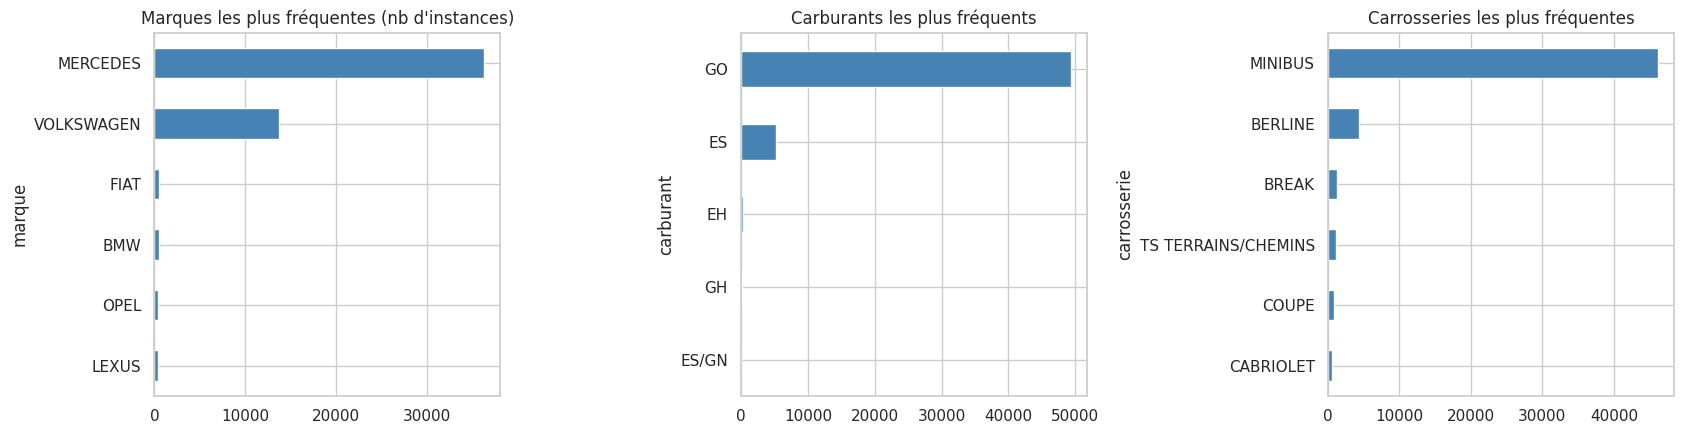

Part des deux premières marques : 90.7%
Part du gazole (GO) : 89.7% | Part des MINIBUS : 83.8%
Nombre de marques : 44 | nombre de modèles : 427 | nombre de groupes (marque | description) : 3817


In [172]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
df["marque"].value_counts().head(6).plot.barh(ax=ax[0], color="steelblue"); ax[0].invert_yaxis()
ax[0].set_title("Marques les plus fréquentes (nb d'instances)")
df["carburant"].value_counts().head(5).plot.barh(ax=ax[1], color="steelblue"); ax[1].invert_yaxis()
ax[1].set_title("Carburants les plus fréquents")
df["carrosserie"].value_counts().head(6).plot.barh(ax=ax[2], color="steelblue"); ax[2].invert_yaxis()
ax[2].set_title("Carrosseries les plus fréquentes")
plt.tight_layout(); plt.show()

print("Part des deux premières marques :", f"{df['marque'].value_counts(normalize=True).head(2).sum():.1%}")
print("Part du gazole (GO) :", f"{(df['carburant'] == 'GO').mean():.1%}", "| Part des MINIBUS :", f"{(df['carrosserie'] == 'MINIBUS').mean():.1%}")
print("Nombre de marques :", df["marque"].nunique(), "| nombre de modèles :", df["modele"].nunique(),
      "| nombre de groupes (marque | description) :", df["groupe"].nunique())


Le jeu est très déséquilibré entre constructeurs : Mercedes et Volkswagen représentent 90,7 % des instances (sur 44 marques). 89,7 % sont des diesels (`GO`) et 83,8 % des `MINIBUS`. Il s'agit donc surtout d'utilitaires et de monospaces de ces deux marques, ce qui ne représente pas le marché français dans son ensemble. Nos modèles seront surtout fiables sur ce type de véhicules et il faudra le préciser dans les conclusions.


## 4. Valeurs manquantes

In [173]:
# 1. Valeurs manquantes
def table_manquants(d):
    t = pd.DataFrame({"Nb manquants": d.isna().sum(), "%": (d.isna().mean() * 100).round(2)})
    return t[t["Nb manquants"] > 0].sort_values("%", ascending=False)

print("Avant traitement :")
display(table_manquants(df))

# 2. Les manquants dépendent du carburant : on regarde par carburant (principaux seulement)
top_fuel = df["carburant"].value_counts().head(2).index
by_fuel = df[df["carburant"].isin(top_fuel)].groupby("carburant")[["hc_g_km", "hcnox_g_km", "particules_g_km", "co_g_km"]].agg(lambda s: s.isna().mean() * 100).round(1)
print("Pourcentage de manquants par carburant :")
display(by_fuel)


Avant traitement :


,Nb manquants,%
hc_g_km,45237,82.24
hcnox_g_km,9847,17.90
particules_g_km,2638,4.80
co_g_km,124,0.23
nox_g_km,124,0.23
norme_euro,55,0.10
conso_urb,9,0.02
conso_exurb,9,0.02


Pourcentage de manquants par carburant :


,hc_g_km,hcnox_g_km,particules_g_km,co_g_km
carburant,,,,
ES,1.6,99.7,46.3,1.4
GO,91.4,8.6,0.0,0.0


In [174]:
# 3. Reconstruction de HC+NOx quand HC et NOx sont connus
mask = df["hcnox_g_km"].isna() & df["hc_g_km"].notna() & df["nox_g_km"].notna()
df.loc[mask, "hcnox_g_km"] = df.loc[mask, "hc_g_km"] + df.loc[mask, "nox_g_km"]
print(f"HC+NOx reconstruit pour {mask.sum()} instances.")

# 4. HC seul n'est utile qu'aux essences et reste trop vide : on l'abandonne
df = df.drop(columns="hc_g_km")

print("\nAprès traitement :")
display(table_manquants(df))


HC+NOx reconstruit pour 9723 instances.

Après traitement :


,Nb manquants,%
particules_g_km,2638,4.80
nox_g_km,124,0.23
co_g_km,124,0.23
hcnox_g_km,124,0.23
norme_euro,55,0.10
conso_exurb,9,0.02
conso_urb,9,0.02


Les valeurs manquantes dépendent du carburant. HC+NOx n'est renseigné que pour 0,3 % des essences contre 91 % des diesels, et c'est l'inverse pour HC seul (manquant pour 91 % des diesels). On peut alors supposer que la réglementation ne fixe pas les mêmes polluants à mesurer selon le carburant. Les particules manquent pour 46 % des essences et presque jamais pour les diesels.

On a alors 3 options : supprimer les instances concernées, supprimer l'attribut, ou imputer une valeur. Supprimer les instances nous ferait perdre beaucoup d'essences, donc on ne l'utilise pas. Ce qu'on a fait :
* reconstruction de HC+NOx avec `HC+NOx = HC + NOx` quand les deux sont connus : 9 723 instances complétées, il n'en manque plus que 124 ;
* suppression de l'attribut `hc_g_km` (option 2), car il a 82 % de manquants sur l'ensemble du jeu. Il est pourtant renseigné pour presque toutes les essences : on perd donc cette information pour elles (environ 9 % du jeu). C'est une limite qu'on garde en tête ;
* pour le reste (particules 4,8 %, CO et NOx 0,2 %, 9 consommations, 55 normes Euro), imputation dans le pipeline (option 3) : médiane pour les attributs numériques, valeur la plus fréquente pour les catégoriels. On ajoute aussi une colonne qui indique si la valeur manquait (`add_indicator=True` dans `SimpleImputer`), parce que le fait qu'une valeur manque dépend du carburant.

L'imputation se fait dans le pipeline, après le découpage, pour que les médianes soient calculées sur le train uniquement.


## 5. Distributions, échelles et valeurs extrêmes

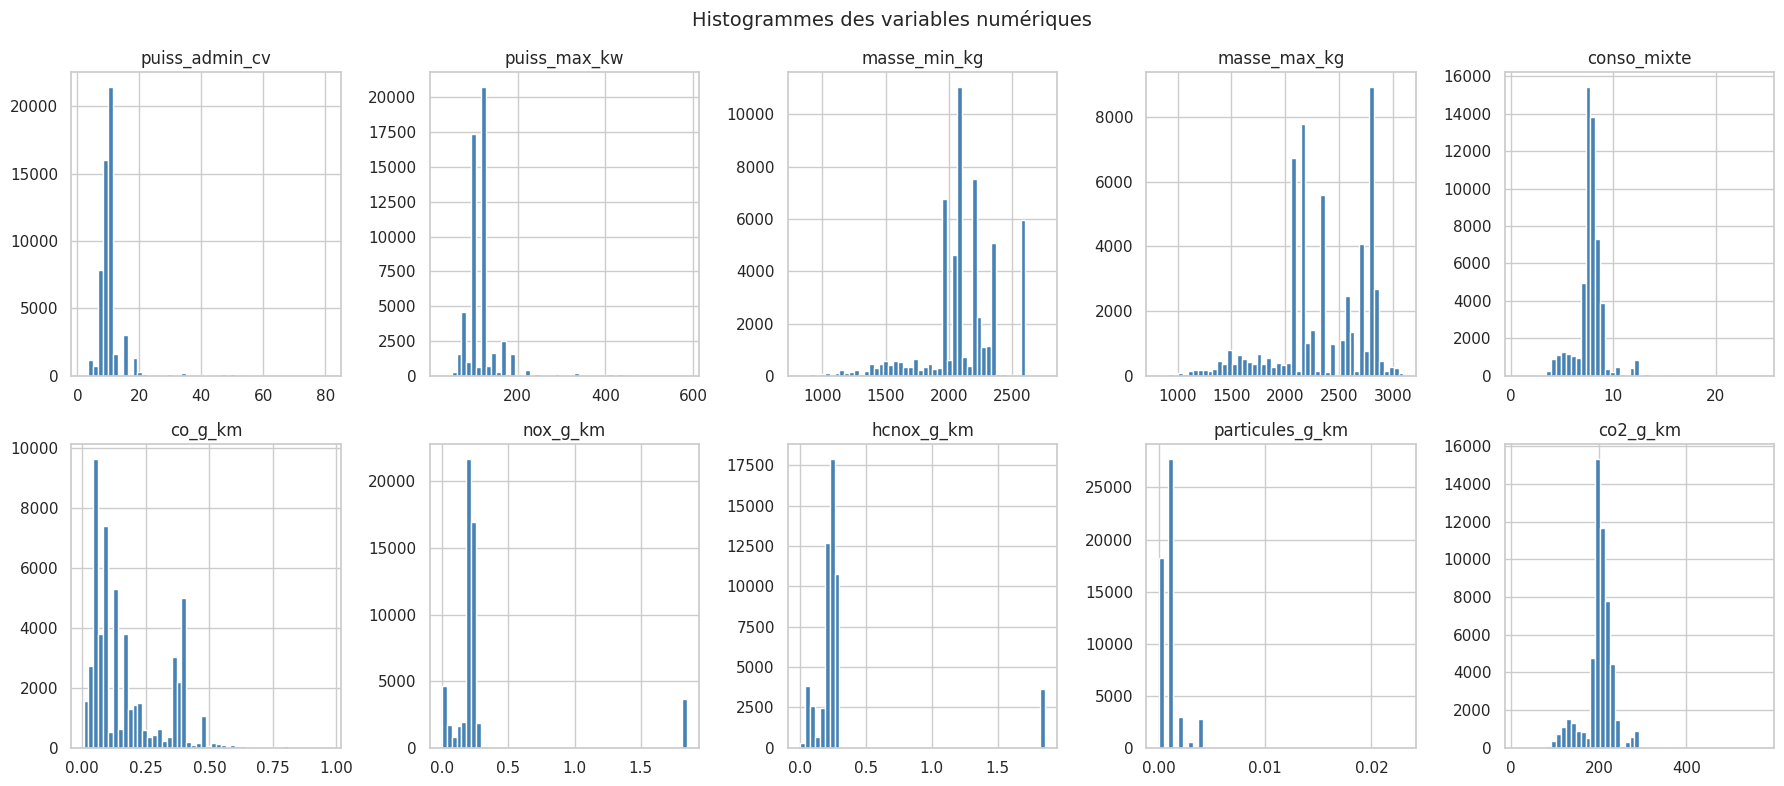

,mean,25%,50%,75%,max
puiss_admin_cv,10.557,9.000,10.000,10.000,81.000
puiss_max_kw,119.039,100.000,120.000,120.000,585.000
masse_min_kg,2102.825,1982.000,2076.000,2246.000,2760.000
masse_max_kg,2341.912,2075.000,2355.000,2709.000,3094.000
conso_mixte,7.765,7.300,7.800,8.300,24.500
co_g_km,0.181,0.061,0.137,0.297,0.968
nox_g_km,0.299,0.197,0.214,0.228,1.846
hcnox_g_km,0.323,0.216,0.238,0.263,1.860
particules_g_km,0.001,0.000,0.001,0.001,0.023
co2_g_km,201.718,193.000,205.000,216.000,572.000


In [176]:
num_dist = ["puiss_admin_cv", "puiss_max_kw", "masse_min_kg", "masse_max_kg", "conso_mixte",
            "co_g_km", "nox_g_km", "hcnox_g_km", "particules_g_km", "co2_g_km"]
df[num_dist].hist(bins=50, figsize=(18, 8), color="steelblue", layout=(2, 5))
plt.suptitle("Histogrammes des variables numériques", fontsize=14); plt.tight_layout(); plt.show()

# Quartiles et extrêmes :
display(df[num_dist].describe().T[["mean", "25%", "50%", "75%", "max"]].round(3))


Plusieurs histogrammes sont « tail heavy » : ils s'étendent loin à droite de la médiane. Par exemple 75 % des véhicules ont au plus 120 kW mais le maximum est 585 kW, et pour le NOx le 3e quartile est 0,23 g/km alors que le maximum est 1,85 g/km. Les échelles sont aussi très différentes (la masse est autour de 2 000 kg alors que les polluants sont sous 2 g/km).

On a deux mises à l'échelle possibles : min-max ou standardisation. On choisit la standardisation (`StandardScaler`) car le min-max est très sensible aux valeurs extrêmes, qui sont nombreuses ici. C'est utile pour les modèles linéaires régularisés et la descente de gradient ; pour les modèles à base d'arbres ça ne change rien. Une autre piste serait de passer au logarithme les attributs les plus étalés (puissances, polluants) ; on la gardera pour l'étape 2 si les modèles linéaires en ont besoin.


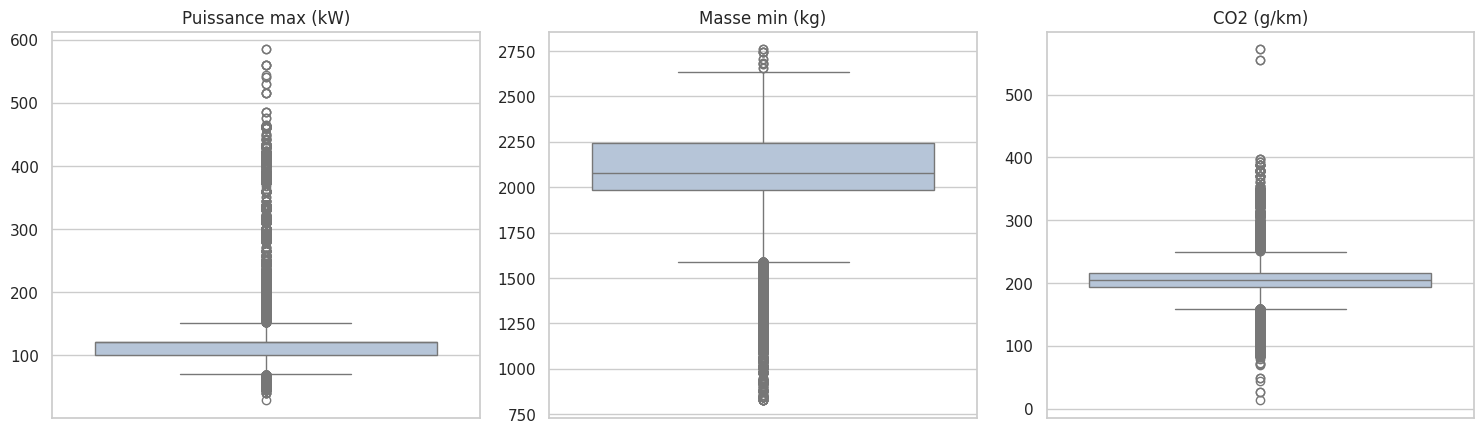

5 plus fortes émissions de CO2 :


,marque,description,carburant,puiss_max_kw,masse_min_kg,co2_g_km
197,ASTON MARTIN,ONE-77,ES,559.299988,1815,572.0
198,ASTON MARTIN,ONE-77,ES,559.299988,1815,572.0
195,ASTON MARTIN,ONE-77,ES,559.299988,1815,555.0
196,ASTON MARTIN,ONE-77,ES,559.299988,1815,555.0
2605,LAMBORGHINI,VENENO,ES,545.000000,1640,398.0


5 plus fortes puissances :


,marque,description,carburant,puiss_max_kw,masse_min_kg,co2_g_km
1478,FERRARI,LaFerrari,EH,585.000000,1565,330.0
1479,FERRARI,LaFerrari,EH,585.000000,1565,330.0
195,ASTON MARTIN,ONE-77,ES,559.299988,1815,555.0
196,ASTON MARTIN,ONE-77,ES,559.299988,1815,555.0
197,ASTON MARTIN,ONE-77,ES,559.299988,1815,572.0


Instances avec conso_urb = 0 :


,marque,description,carburant,puiss_max_kw,masse_min_kg,co2_g_km,hybride,conso_urb
54973,VOLVO,V60 PLUG-IN HYBRID D6 Geartronic 6 AWD,GL,158.0,1949,48.0,oui,0.0


5 plus faibles émissions de CO2 :


,marque,description,carburant,puiss_max_kw,masse_min_kg,co2_g_km,hybride
1074,BMW,i3 avec Prolongateur d'autonomie,EE,28.0,1390,13.0,oui
1211,CHEVROLET,VOLT,EE,63.0,1732,27.0,oui
39903,OPEL,AMPERA,EE,63.0,1732,27.0,oui
39588,MITSUBISHI,OUTLANDER PHEV,EE,89.0,1885,44.0,oui
54973,VOLVO,V60 PLUG-IN HYBRID D6 Geartronic 6 AWD,GL,158.0,1949,48.0,oui


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, col, titre in zip(ax, ["puiss_max_kw", "masse_min_kg", "co2_g_km"], ["Puissance max (kW)", "Masse min (kg)", "CO2 (g/km)"]):
    sns.boxplot(y=df[col], ax=a, color="lightsteelblue"); a.set_title(titre); a.set_ylabel("")
plt.tight_layout(); plt.show()

# Recherche valeurs extrêmes : on regarde les instances concernées avant de décider.
cols_vue = ["marque", "description", "carburant", "puiss_max_kw", "masse_min_kg", "co2_g_km"]
print("5 plus fortes émissions de CO2 :")
display(df.nlargest(5, "co2_g_km")[cols_vue])
print("5 plus fortes puissances :")
display(df.nlargest(5, "puiss_max_kw")[cols_vue])
print("Instances avec conso_urb = 0 :")
display(df[df["conso_urb"] == 0][cols_vue + ["hybride", "conso_urb"]])
print("5 plus faibles émissions de CO2 :")
display(df.nsmallest(5, "co2_g_km")[cols_vue + ["hybride"]])


Pour les valeurs extrêmes, on pouvait les supprimer, les plafonner ou les garder. On a d'abord regardé à quoi elles correspondent :
* les plus gros CO2 et les plus grosses puissances sont des supercars (Aston Martin ONE-77 à 572 g/km, Lamborghini Veneno, Ferrari LaFerrari à 585 kW) ;
* les plus petits CO2 (de 13 à 48 g/km) sont des hybrides rechargeables (BMW i3 REx, Volt/Ampera, Outlander PHEV, Volvo V60) ;
* la seule instance avec `conso_urb = 0` est la Volvo V60 hybride rechargeable, une valeur plausible pour ce type de véhicule.

On les garde : ce sont de vrais véhicules, et les enlever rendrait l'évaluation trop optimiste. À noter pour la suite : la RMSE est plus sensible à ces valeurs que la MAE (cours 02), donc on regardera les deux.


## 6. Variables cibles et découpage train / test

,Nb,%
etiquette_energie,,
A,388,0.71
B,1542,2.80
C,2525,4.59
D,1795,3.26
E,16457,29.92
F,30206,54.92
G,2090,3.80


Part de CO2 > 160 g/km (malus_eleve = 1) : 88.6%


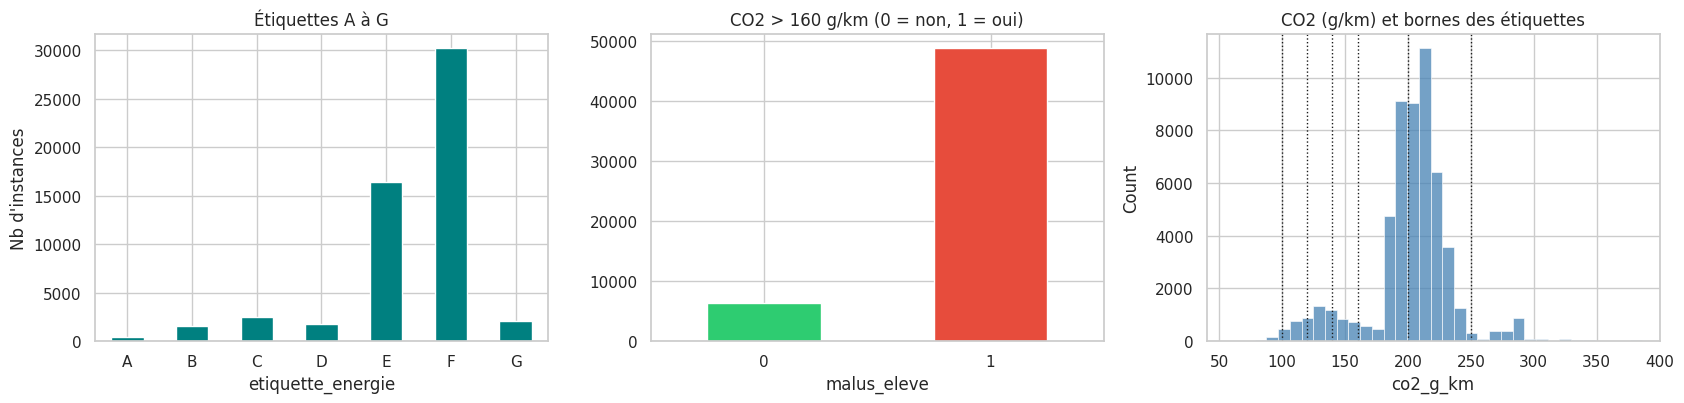

In [ ]:
order = LABELS
tab = pd.DataFrame({"Nb": df["etiquette_energie"].value_counts().reindex(order),
                    "%": (df["etiquette_energie"].value_counts(normalize=True).reindex(order) * 100).round(2)})
display(tab)
print(f"Part de CO2 > 160 g/km (malus_eleve = 1) : {df['malus_eleve'].mean():.1%}")

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
tab["Nb"].plot(kind="bar", color="teal", ax=ax[0], rot=0); ax[0].set_title("Étiquettes A à G"); ax[0].set_ylabel("Nb d'instances")
df["malus_eleve"].value_counts().sort_index().plot(kind="bar", color=["#2ecc71", "#e74c3c"], ax=ax[1], rot=0)
ax[1].set_title("CO2 > 160 g/km (0 = non, 1 = oui)")
sns.histplot(df["co2_g_km"], bins=60, ax=ax[2], color="steelblue")
for b in BINS[1:-1]: ax[2].axvline(b, color="k", ls=":", lw=1)
ax[2].set_title("CO2 (g/km) et bornes des étiquettes"); ax[2].set_xlim(40, 400)
plt.tight_layout(); plt.show()


Les classes sont très déséquilibrées : F (54,9 %) et E (29,9 %) représentent presque tout, les autres sont rares (A 0,7 %, B 2,8 %, C 4,6 %, D 3,3 %, G 3,8 %). Pour la cible binaire c'est l'inverse : 88,6 % des instances dépassent 160 g/km. Le CO2 est assez concentré (médiane à 205 g/km, la moitié des instances entre 193 et 216), donc un modèle peut avoir une bonne accuracy sans être bon, comme avec le `DummyClassifier` du cours 03.

Pour la suite on prévoit donc :
* de regarder la précision, le rappel, le F1 et la matrice de confusion, pas seulement l'accuracy ;
* de faire éventuellement du sur-échantillonnage, mais seulement sur le train, après le découpage ;
* une validation croisée groupée, la même pour tous les modèles. Il faudra vérifier que chaque pli contient bien des instances de chaque classe, car la classe A est très rare (0,7 %) et les groupes sont gros.


In [ ]:
# Attributs d'entrée bruts servant à comparer deux découpages
def part_test_deja_vu(train, test, cols=FEAT_BRUTES):
    """Part des instances de test dont les attributs d'entrée existent à l'identique dans le train."""
    m = test[cols].merge(train[cols].drop_duplicates(), on=cols, how="left", indicator=True)
    return (m["_merge"] == "both").mean()

# Découpage 1 : aléatoire stratifié sur l'étiquette
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(sss.split(df, df["etiquette_energie"]))
rand_train, rand_test = df.iloc[tr_idx], df.iloc[te_idx]

# Découpage 2 : groupé
''' GroupShuffleSplit tire les groupes au hasard : comme certains groupes sont très gros, la taille du test
    et la répartition des étiquettes varient d'un tirage à l'autre. On fait 100 tirages et on garde celui
    dont la taille (cible 20 %) et la répartition des étiquettes sont les plus proches de la base complète.'''
gss = GroupShuffleSplit(n_splits=100, test_size=0.2, random_state=SEED)
ref = df["etiquette_energie"].value_counts(normalize=True).reindex(LABELS)
candidats = []
for k, (tr, te) in enumerate(gss.split(df, groups=df["groupe"]), 1):
    rep = df.iloc[te]["etiquette_energie"].value_counts(normalize=True).reindex(LABELS)
    ecart_etiq = (rep - ref).abs().sum() * 100            # en points de %
    ecart_taille = abs(len(te) / len(df) - 0.2) * 100
    candidats.append({"tirage": k, "% test": round(len(te) / len(df) * 100, 1),
                      "écart étiquettes (pts)": round(ecart_etiq, 1), "score": round(ecart_etiq + ecart_taille, 1),
                      "tr": tr, "te": te})
candidats = sorted(candidats, key=lambda c: c["score"])
choix = candidats[0]
print("5 meilleurs tirages sur 100 :")
display(pd.DataFrame(candidats[:5]).drop(columns=["tr", "te"]).set_index("tirage"))
print(f"Tirage retenu : {choix['tirage']}")
train_set = df.iloc[choix["tr"]].reset_index(drop=True)
test_set = df.iloc[choix["te"]].reset_index(drop=True)

print(f"Découpage aléatoire : {part_test_deja_vu(rand_train, rand_test):.1%} des instances de test ont une jumelle exacte dans le train")
print(f"Découpage groupé    : {part_test_deja_vu(train_set, test_set):.1%} des instances de test ont une jumelle exacte dans le train")
print(f"Taille du plus gros groupe : {df['groupe'].value_counts().max()} instances")
modeles_train = set(zip(train_set['marque'], train_set['modele']))
print(f"Instances de test dont le modèle (marque + modèle) est aussi dans le train : {pd.Series(list(zip(test_set['marque'], test_set['modele']))).isin(modeles_train).mean():.1%}")
print(f"Groupes communs au train et au test (groupé) : {len(set(train_set['groupe']) & set(test_set['groupe']))}")
print(f"\nTaille train : {len(train_set)} | test : {len(test_set)} ({len(test_set)/len(df):.1%})")

comp = pd.DataFrame({"Base complète (%)": df["etiquette_energie"].value_counts(normalize=True) * 100,
                     "Test groupé (%)": test_set["etiquette_energie"].value_counts(normalize=True) * 100,
                     "Test aléatoire (%)": rand_test["etiquette_energie"].value_counts(normalize=True) * 100}).reindex(LABELS).round(2)
display(comp)
print(f"Part CO2 > 160 : base {df['malus_eleve'].mean():.1%} | train {train_set['malus_eleve'].mean():.1%} | test {test_set['malus_eleve'].mean():.1%}")


5 meilleurs tirages sur 100 :


,% test,écart étiquettes (pts),score
tirage,,,
73,23.3,2.1,5.4
4,20.0,5.5,5.5
60,20.3,5.3,5.6
33,18.2,4.2,6.1
16,19.6,6.7,7.1


Tirage retenu : 73
Découpage aléatoire : 94.3% des instances de test ont une jumelle exacte dans le train
Découpage groupé    : 28.2% des instances de test ont une jumelle exacte dans le train
Taille du plus gros groupe : 5874 instances
Instances de test dont le modèle (marque + modèle) est aussi dans le train : 99.0%
Groupes communs au train et au test (groupé) : 0

Taille train : 42196 | test : 12807 (23.3%)


,Base complète (%),Test groupé (%),Test aléatoire (%)
etiquette_energie,,,
A,0.71,0.62,0.71
B,2.80,2.57,2.80
C,4.59,4.37,4.59
D,3.26,3.12,3.26
E,29.92,30.96,29.92
F,54.92,54.54,54.91
G,3.80,3.82,3.80


Part CO2 > 160 : base 88.6% | train 88.4% | test 89.3%


Les sections 3 à 5 ( `describe`, histogrammes, valeurs manquantes, valeurs extrêmes) ont été faites sur toute la base. À partir d'ici, tout est fait sur le train, pour limiter le biais de « data snooping ».

Avec le découpage stratifié du cours (`StratifiedShuffleSplit`), 94,3 % des instances du test ont une jumelle exacte (mêmes entrées) dans le train. Un modèle pourrait donc juste « reconnaître » ces instances, et l'erreur mesurée sur le test serait trop optimiste. On utilise donc `GroupShuffleSplit`, une variante de scikit-learn : toutes les instances d'une même description commerciale (marque + description) vont du même côté, et aucun groupe n'est à la fois dans le train et dans le test.

Ce découpage reste un compromis. 28,2 % des instances du test ont encore une jumelle exacte dans le train (des descriptions différentes avec les mêmes caractéristiques), et 99,0 % appartiennent à un modèle (par exemple le Viano) qui a aussi d'autres versions dans le train. Grouper par modèle serait plus strict, mais un seul modèle regroupe environ un quart du jeu, ce qui empêche d'avoir un test équilibré.

Comme certains groupes sont très gros (jusqu'à 5 874 instances), un seul tirage peut donner un test trop petit ou mal équilibré. On fait donc 100 tirages et on garde celui dont la taille et la répartition des classes sont les plus proches de la base complète. Le tirage retenu donne 42 196 instances de train et 12 807 de test (23,3 %). Les proportions des classes du test sont proches de celles de la base (2,1 points d'écart au total, par exemple 54,5 % de F contre 54,9 %) et 89,3 % des instances du test dépassent 160 g/km contre 88,6 % au total.


## 7. Nouveaux attributs et corrélations
On crée 4 nouveaux attributs avec la fonction `add_features`. Elle fait seulement des calculs instance par instance (rien n'est appris sur les données), donc on peut l'appliquer au train et au test sans fuite d'information.
* `type_boite` et `nb_rapports`, tirés de `boite_rapports` (« M 6 » donne boîte manuelle à 6 rapports). Pour les boîtes à variation continue (« V 0 », 298 instances du train), il n'y a pas de nombre de rapports : on laisse la valeur manquante, elle sera imputée dans le pipeline ;
* `puiss_par_tonne` : puissance divisée par la masse ;
* `ecart_masse_kg` : masse maximale moins masse minimale.


In [ ]:
def add_features(d):
    """Nouveaux attributs calculés instance par instance : la fonction peut être appliquée telle quelle au train et au test."""
    d = d.copy()
    d["type_boite"] = d["boite_rapports"].astype(str).str.strip().str[0]
    d["nb_rapports"] = pd.to_numeric(d["boite_rapports"].astype(str).str.extract(r"(\d+)", expand=False), errors="coerce")
    d.loc[d["type_boite"] == "V", "nb_rapports"] = np.nan   # boîte à variation continue (« V 0 ») : pas de nombre de rapports
    d["puiss_par_tonne"] = d["puiss_max_kw"] / (d["masse_min_kg"] / 1000.0)
    d["ecart_masse_kg"] = d["masse_max_kg"] - d["masse_min_kg"]
    return d

train_set = add_features(train_set)
test_set = add_features(test_set)
display(train_set[["boite_rapports", "type_boite", "nb_rapports", "puiss_par_tonne", "ecart_masse_kg"]].head(5))
print(train_set["type_boite"].value_counts().to_dict())


,boite_rapports,type_boite,nb_rapports,puiss_par_tonne,ecart_masse_kg
0,M 6,M,6.0,97.674419,0
1,M 6,M,6.0,94.533762,0
2,M 6,M,6.0,63.897764,0
3,M 6,M,6.0,63.897764,0
4,M 6,M,6.0,79.872204,0


{'M': 25254, 'A': 16557, 'V': 298, 'D': 86, 'S': 1}


Corrélation de chaque attribut numérique avec le CO2 (jeu d'entraînement) :


,corr avec CO2
conso_mixte,0.969
conso_exurb,0.968
conso_urb,0.909
masse_min_kg,0.615
masse_max_kg,0.514
puiss_admin_cv,0.465
puiss_max_kw,0.349
particules_g_km,0.208
nox_g_km,0.158
hcnox_g_km,0.154


Corrélations entre attributs d'entrée :
  masse_min_kg / masse_max_kg : 0.782
  puiss_max_kw / puiss_admin_cv : 0.974
  masse_min_kg / puiss_max_kw : -0.021
  nox_g_km / hcnox_g_km : 0.999
  conso_mixte / co2_g_km : 0.969


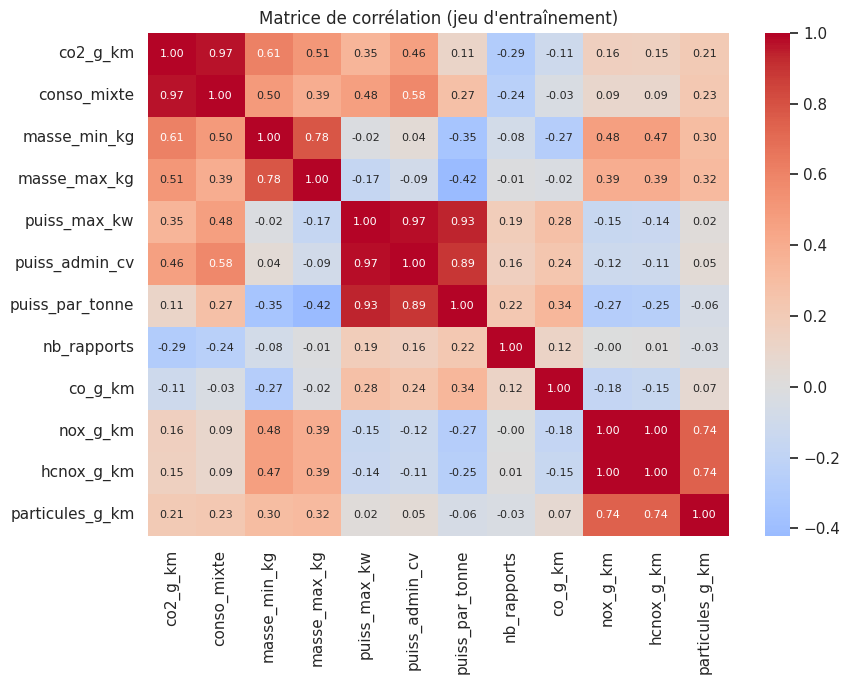

In [ ]:
explore = train_set.copy()

corr = explore.drop(columns=["malus_eleve"]).select_dtypes(include=[np.number]).corr()
print("Corrélation de chaque attribut numérique avec le CO2 :")
display(corr["co2_g_km"].drop("co2_g_km").sort_values(ascending=False).round(3).to_frame("corr avec CO2"))

# Corrélations entre attributs d'entrée (colinéarité)
print("Corrélations entre attributs d'entrée :")
paires = [("masse_min_kg", "masse_max_kg"), ("puiss_max_kw", "puiss_admin_cv"), ("masse_min_kg", "puiss_max_kw"), ("nox_g_km", "hcnox_g_km"), ("conso_mixte", "co2_g_km")]
for a, b in paires:
    print(f"  {a} / {b} : {explore[a].corr(explore[b]):.3f}")

plt.figure(figsize=(9, 7))
cols_h = ["co2_g_km", "conso_mixte", "masse_min_kg", "masse_max_kg", "puiss_max_kw", "puiss_admin_cv", "puiss_par_tonne", "nb_rapports", "co_g_km", "nox_g_km", "hcnox_g_km", "particules_g_km"]
sns.heatmap(explore[cols_h].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, annot_kws={"size": 8})
plt.title("Matrice de corrélation (jeu d'entraînement)"); plt.tight_layout(); plt.show()


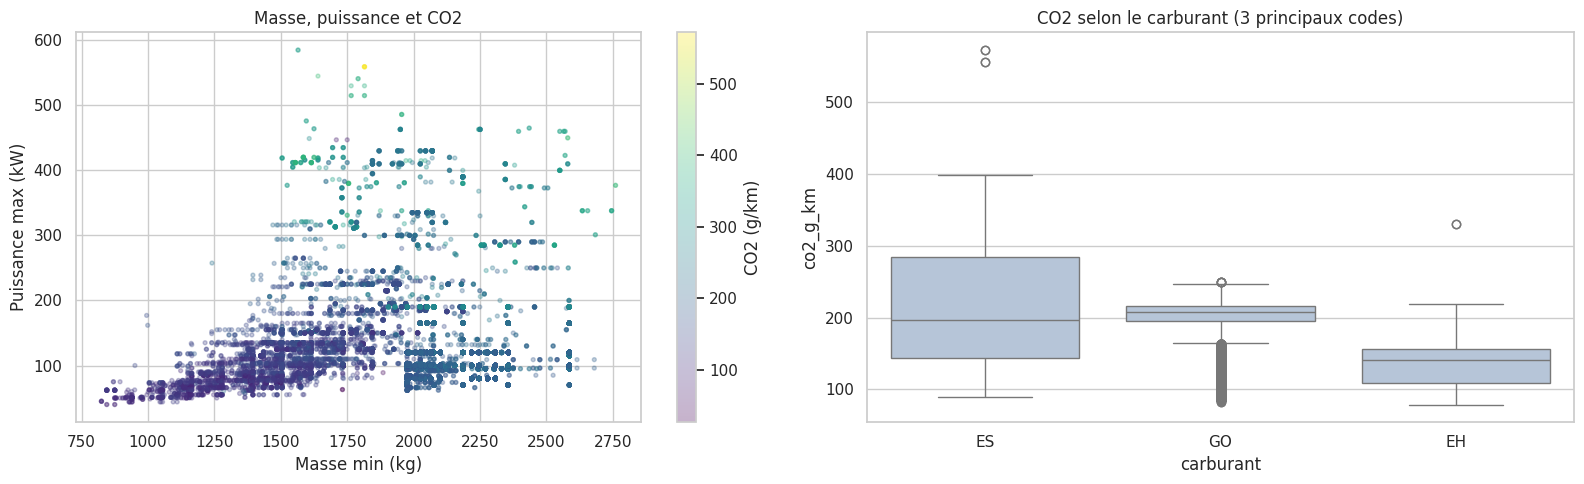

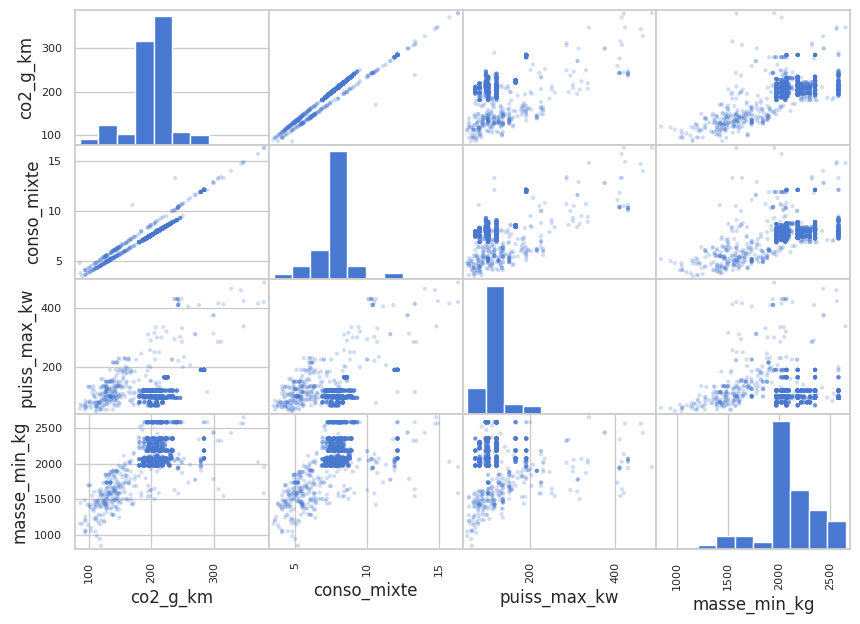

CO2 médian par carburant (principaux codes) :


,count,median
carburant,,
GO,37361,207.0
ES,4368,196.0
EH,293,141.0
GH,47,116.0


CO2 médian par type de boîte :


,count,median
type_boite,,
M,25254,198.0
A,16557,216.0
V,298,137.5
D,86,125.0


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sc = ax[0].scatter(explore["masse_min_kg"], explore["puiss_max_kw"], c=explore["co2_g_km"], cmap="viridis", alpha=0.3, s=8)
ax[0].set_xlabel("Masse min (kg)"); ax[0].set_ylabel("Puissance max (kW)"); ax[0].set_title("Masse, puissance et CO2")
plt.colorbar(sc, ax=ax[0], label="CO2 (g/km)")
top = explore["carburant"].value_counts().head(3).index
sns.boxplot(data=explore[explore["carburant"].isin(top)], x="carburant", y="co2_g_km", ax=ax[1], color="lightsteelblue")
ax[1].set_title("CO2 selon le carburant")
plt.tight_layout(); plt.show()

echantillon = explore[["co2_g_km", "conso_mixte", "puiss_max_kw", "masse_min_kg"]].dropna().sample(2000, random_state=SEED)
scatter_matrix(echantillon, figsize=(10, 7), alpha=0.25)
plt.show()

print("CO2 médian par carburant :")
display(explore.groupby("carburant")["co2_g_km"].agg(["count", "median"]).sort_values("count", ascending=False).head(4).round(1))
print("CO2 médian par type de boîte :")
display(explore.groupby("type_boite")["co2_g_km"].agg(["count", "median"]).sort_values("count", ascending=False).head(4).round(1))


Coefficients de corrélation de Pearson, calculés sur le jeu d'entraînement :
* la consommation mixte et la consommation extra-urbaine sont à 0,97 avec le CO2 (0,91 pour l'urbaine), c'est pour cela qu'on les enlève dans le pipeline B ;
* sans les consommations, c'est surtout la masse qui va jouer (0,61 pour `masse_min_kg`, 0,51 pour `masse_max_kg`), puis la puissance administrative (0,46) et la puissance maximale (0,35). Le nombre de rapports est corrélé négativement (−0,29) : plus de rapports, moins de CO2. `puiss_par_tonne` est peu corrélée (0,11), mais une corrélation linéaire nulle ne veut pas dire qu'il n'y a pas de lien, donc on la garde pour les modèles non linéaires ;
* certains attributs sont très liés entre eux : les deux puissances (0,97) et les deux masses (0,78). La masse et la puissance, elles, ne sont presque pas corrélées (−0,02) ;
* `nox_g_km` et `hcnox_g_km` sont corrélés à 0,999, surtout parce que les diesels sont majoritaires. On retire `hcnox_g_km` des entrées pour ne pas répéter la même information. Avec la suppression de `hc_g_km` (section 4), on ne garde donc aucune mesure des hydrocarbures pour les essences : on testera à l'étape 2 si remettre `hcnox_g_km` améliore les résultats ;
* le CO2 médian est de 207 g/km pour le gazole, 196 pour l'essence, 141 pour l'essence hybride et 116 pour le gazole hybride. Les boîtes automatiques émettent plus (216) que les manuelles (198).


## 8. Pipelines de préparation
On regroupe la préparation dans un `ColumnTransformer`, qui sépare attributs numériques et catégoriels. Les transformations sont apprises sur le train (`fit_transform`) puis appliquées au test (`transform`).
* Attributs numériques : imputation par la médiane avec indicateur de manquant, puis `StandardScaler`.
* Norme Euro : `OrdinalEncoder` avec l'ordre EURO5 < EEV < EURO6. Cet ordre est un choix de notre part ; EEV concerne 1 830 instances. Les manquants prennent la valeur la plus fréquente.
* Attributs catégoriels (marque, carburant, hybride, type de boîte, carrosserie, gamme) : valeur la plus fréquente pour les manquants puis `OneHotEncoder`. Les modalités qui apparaissent moins de 30 fois sont regroupées (`min_frequency=30`), sinon on aurait 44 colonnes de marques dont la plupart presque vides.
* `groupe` n'est pas une entrée, il sert seulement au découpage.

Les polluants (CO, NOx, particules) sont mesurés pendant le même essai que le CO2, comme les consommations. On les garde quand même dans le pipeline B car, contrairement à la consommation, ils ne sont pas proportionnels au CO2 (corrélations de −0,12 à 0,21) : ils renseignent plutôt sur la technologie du moteur. Choix qu'on vérifiera à l'étape 2 en comparant avec un pipeline sans polluants.

On obtient ainsi 76 colonnes pour le pipeline B et 81 pour le pipeline A, sans aucune valeur manquante.


In [ ]:
# Deux jeux d'attributs d'entrée :
#  - pipeline B : sans les consommations
#  - pipeline A : avec les consommations, pour mesurer l'écart
NUM_B = ["puiss_admin_cv", "puiss_max_kw", "masse_min_kg", "masse_max_kg", "ecart_masse_kg",
         "nb_rapports", "puiss_par_tonne", "co_g_km", "nox_g_km", "particules_g_km"]   # hcnox_g_km retiré : redondant avec nox_g_km
CONSO = ["conso_urb", "conso_exurb", "conso_mixte"]
ORD = ["norme_euro"]
CAT = ["marque", "carburant", "hybride", "type_boite", "carrosserie", "gamme"]

def make_preprocessor(avec_conso=False):
    num_cols = NUM_B + (CONSO if avec_conso else [])
    num = Pipeline([("imputer", SimpleImputer(strategy="median", add_indicator=True)),   # add_indicator : garde la trace du manquant
                    ("scaler", StandardScaler())])
    ordi = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("encoder", OrdinalEncoder(categories=[["EURO5", "EEV", "EURO6"]], handle_unknown="use_encoded_value", unknown_value=-1))])
    cat = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False))])
    return ColumnTransformer([("num", num, num_cols), ("ord", ordi, ORD), ("cat", cat, CAT)])

y_train, y_test = train_set["co2_g_km"], test_set["co2_g_km"]
features_B = NUM_B + ORD + CAT
features_A = NUM_B + CONSO + ORD + CAT

pre_B = make_preprocessor(avec_conso=False)
X_train_B = pre_B.fit_transform(train_set[features_B])     # apprentissage des paramètres sur le train uniquement
X_test_B = pre_B.transform(test_set[features_B])
pre_A = make_preprocessor(avec_conso=True)
X_train_A = pre_A.fit_transform(train_set[features_A])
X_test_A = pre_A.transform(test_set[features_A])

print(f"Pipeline B (sans conso) : train {X_train_B.shape} | test {X_test_B.shape} | NaN restants : {np.isnan(X_train_B).sum() + np.isnan(X_test_B).sum()}")
print(f"Pipeline A (avec conso) : train {X_train_A.shape} | test {X_test_A.shape} | NaN restants : {np.isnan(X_train_A).sum() + np.isnan(X_test_A).sum()}")
print("\nColonnes manquantes signalées par un indicateur :", [n for n in pre_B.get_feature_names_out() if "missingindicator" in n])
pre_B


Pipeline B (sans conso) : train (42196, 76) | test (12807, 76) | NaN restants : 0
Pipeline A (avec conso) : train (42196, 81) | test (12807, 81) | NaN restants : 0

Colonnes manquantes signalées par un indicateur : ['num__missingindicator_nb_rapports', 'num__missingindicator_co_g_km', 'num__missingindicator_nox_g_km', 'num__missingindicator_particules_g_km']


ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(add_indicator=True,
                                                                strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['puiss_admin_cv', 'puiss_max_kw',
                                  'masse_min_kg', 'masse_max_kg',
                                  'ecart_masse_kg', 'nb_rapports',
                                  'puiss_par_tonne', 'co_g_km', 'nox_g_km',
                                  'particules_g_km']),
                                ('ord',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(...
                                                  OrdinalEncoder(categories=[['EURO5',
                                                                              'EEV',
                                                                              'EURO6']],
                                                                 handle_unknown='use_encoded_value',
                                                                 unknown_value=-1))]),
                                 ['norme_euro']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=30,
                                                                sparse_output=False))]),
                                 ['marque', 'carburant', 'hybride',
                                  'type_boite', 'carrosserie', 'gamme'])])

## 9. Vérification du découpage par validation croisée
Pour vérifier si le découpage groupé était nécessaire, on fait une validation croisée en 5 plis (k-fold) avec `cross_val_score` sur le jeu d'entraînement. On prend un modèle simple et régularisé, Ridge, sur le pipeline B, et on compare :
* `KFold` : les plis sont tirés au hasard, donc des instances jumelles peuvent se retrouver à la fois dans l'apprentissage et dans la validation ;
* `GroupKFold` : chaque groupe reste dans un seul pli.

on ne cherche pas pour l'instant un bon modèle mais on voit si la façon de découper change le score.


RMSE de validation (g/km), Ridge sur le pipeline B :


,KFold (aléatoire),GroupKFold (groupé)
pli 1,10.05,9.26
pli 2,10.06,10.35
pli 3,9.83,12.01
pli 4,9.89,12.07
pli 5,10.31,12.53
moyenne,10.03,11.24
écart-type,0.19,1.38


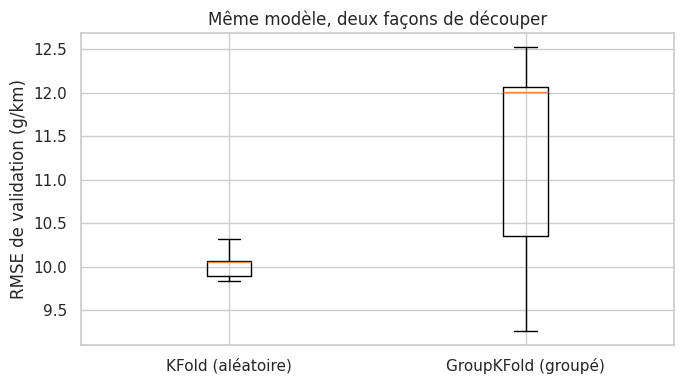

In [ ]:
modele_simple = Pipeline([("pre", make_preprocessor(avec_conso=False)), ("ridge", Ridge(alpha=1.0))])
X_cv, y_cv, g_cv = train_set[features_B], train_set["co2_g_km"], train_set["groupe"]

rmse_kfold = -cross_val_score(modele_simple, X_cv, y_cv, cv=KFold(n_splits=5, shuffle=True, random_state=SEED),
                              scoring="neg_root_mean_squared_error")
rmse_group = -cross_val_score(modele_simple, X_cv, y_cv, cv=GroupKFold(n_splits=5), groups=g_cv,
                              scoring="neg_root_mean_squared_error")

res_cv = pd.DataFrame({"KFold": rmse_kfold, "GroupKFold": rmse_group},
                      index=[f"pli {i}" for i in range(1, 6)])
res_cv.loc["moyenne"] = res_cv.mean()
res_cv.loc["écart-type"] = res_cv.iloc[:5].std()
print("RMSE de validation (g/km), Ridge sur le pipeline B :")
display(res_cv.round(2))

plt.figure(figsize=(7, 4))
plt.boxplot([rmse_kfold, rmse_group])
plt.xticks([1, 2], ["KFold", "GroupKFold"])
plt.ylabel("RMSE de validation (g/km)"); plt.title("Deux façons de découper sur le modèle")
plt.tight_layout(); plt.show()


Avec `KFold`, la RMSE moyenne est de 10,0 g/km et elle varie très peu d'un pli à l'autre (écart-type 0,2). Avec `GroupKFold`, elle monte à 11,24 g/km en moyenne, soit environ 12 % de plus, et elle varie beaucoup plus (de 9,3 à 12,5 selon le pli, écart-type 1,4) : le résultat dépend des véhicules qui tombent dans chaque pli.

Il faut rester prudent : l'écart entre les deux moyennes (1,2 g/km) est du même ordre que la variation entre plis groupés, et on n'a que 5 plis. Mais 4 plis groupés sur 5 sont au-dessus de tous les plis aléatoires. Ça va donc dans le sens de la section 6 : un découpage aléatoire a tendance à surestimer la qualité du modèle. Pour la suite, les validations croisées seront donc groupées (`GroupKFold`) avec le même nombre de plis pour tous les modèles.


## 10. Exploration non supervisée
On utilise les 10 attributs numériques du pipeline B, standardisés, sans la cible ni les consommations. On fait les trois analyses demandées : réduction de dimension (PCA), détection d'anomalies (IsolationForest) et clustering (K-Means).

Variance expliquée : 2 composantes = 58.2% | 90 % atteints avec 5 | 95 % avec 6 composantes (sur 10 attributs)


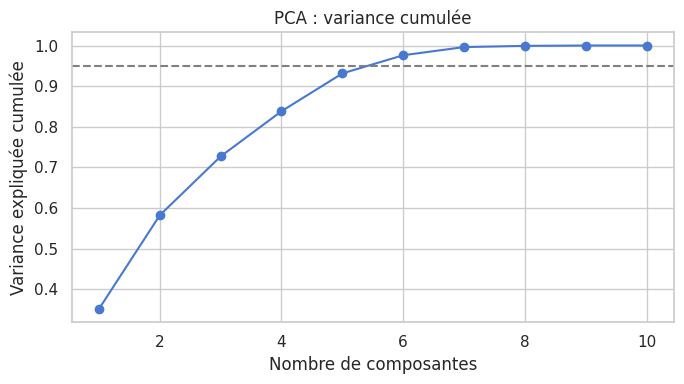

Poids des attributs sur les deux premières composantes :


,PC1,PC2
puiss_admin_cv,0.40,0.39
puiss_max_kw,0.43,0.36
masse_min_kg,-0.28,0.39
masse_max_kg,-0.35,0.39
ecart_masse_kg,-0.25,0.20
nb_rapports,0.12,0.12
puiss_par_tonne,0.49,0.21
co_g_km,0.18,0.14
nox_g_km,-0.27,0.36
particules_g_km,-0.16,0.41


In [ ]:
# Matrice numérique standardisée
explo_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
X_num = explo_pipe.fit_transform(train_set[NUM_B])

pca_full = PCA(random_state=SEED).fit(X_num)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n90, n95 = int(np.argmax(cum >= 0.90)) + 1, int(np.argmax(cum >= 0.95)) + 1
print(f"Variance expliquée : 2 composantes = {cum[1]:.1%} | 90 % atteints avec {n90} | 95 % avec {n95} composantes (sur {len(NUM_B)} attributs)")

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(cum) + 1), cum, marker="o"); plt.axhline(0.95, color="grey", ls="--")
plt.xlabel("Nombre de composantes"); plt.ylabel("Variance expliquée cumulée"); plt.title("PCA : variance cumulée")
plt.tight_layout(); plt.show()

load = pd.DataFrame(pca_full.components_[:2].T, index=NUM_B, columns=["PC1", "PC2"]).round(2)
print("Poids des attributs sur les deux premières composantes :")
display(load)


Les deux premières composantes n'expliquent que 58,2 % de la variance. Il en faut 5 pour atteindre 90 % et 6 pour 95 %, alors qu'on part de 10 attributs : la PCA ne réduit pas beaucoup la dimension ici. La première composante oppose les attributs de puissance (`puiss_par_tonne`, `puiss_max_kw`, `puiss_admin_cv`) aux masses. La deuxième mélange puissance, masse, particules et NOx.

On ne met pas la PCA dans les pipelines : 76 colonnes ne posent pas de problème pour les modèles qu'on prévoit, et on perdrait en interprétabilité. On l'utilise seulement pour visualiser.


In [ ]:
iso = IsolationForest(contamination=0.02, random_state=SEED)
explore["anomalie"] = (iso.fit_predict(X_num) == -1)
print(f"Instances atypiques (taux de 2 % fixé) : {explore['anomalie'].sum()}")

print("\nMarques les plus fréquentes parmi les atypiques :")
display(explore.loc[explore["anomalie"], "marque"].value_counts().head(5).to_frame("nb"))
print("Carburants parmi les atypiques :")
display(explore.loc[explore["anomalie"], "carburant"].value_counts().head(4).to_frame("nb"))
resume = explore.groupby("anomalie")[["co2_g_km", "masse_min_kg", "puiss_max_kw", "nox_g_km", "co_g_km"]].mean().round(2)
display(resume)
print("Part de CO2 > 160 g/km : normaux", f"{explore.loc[~explore['anomalie'], 'malus_eleve'].mean():.1%}",
      "| atypiques", f"{explore.loc[explore['anomalie'], 'malus_eleve'].mean():.1%}")


Instances atypiques (taux de 2 % fixé a priori) : 843

Marques les plus fréquentes parmi les atypiques :


,nb
marque,
MERCEDES,394
LEXUS,64
ASTON MARTIN,46
PORSCHE,38
LAMBORGHINI,28


Carburants parmi les atypiques :


,nb
carburant,
ES,732
GO,98
EH,8
ES/GP,2


,co2_g_km,masse_min_kg,puiss_max_kw,nox_g_km,co_g_km
anomalie,,,,,
False,200.36,2097.49,113.20,0.27,0.18
True,249.75,1892.12,311.84,0.22,0.35


Part de CO2 > 160 g/km : normaux 88.5% | atypiques 87.0%


IsolationForest demande la proportion d'anomalies attendue (`contamination`). On n'a pas de raison d'en choisir une en particulier, on l'a fixée à 2 %, ce qui donne 843 instances. Ce sont surtout des véhicules puissants : 732 sur 843 roulent à l'essence et leur puissance moyenne est de 312 kW contre 113 kW pour le reste. On y trouve 394 instances Mercedes, puis Lexus (64), Aston Martin (46), Porsche (38) et Lamborghini (28). Leur CO2 moyen est plus élevé (250 contre 200 g/km), mais la part qui dépasse 160 g/km est à peu près la même (87,0 % contre 88,5 %).

Comme pour la section 5, on les garde car ce sont de vrais véhicules. On ne fait pas de pipeline séparé sans eux.


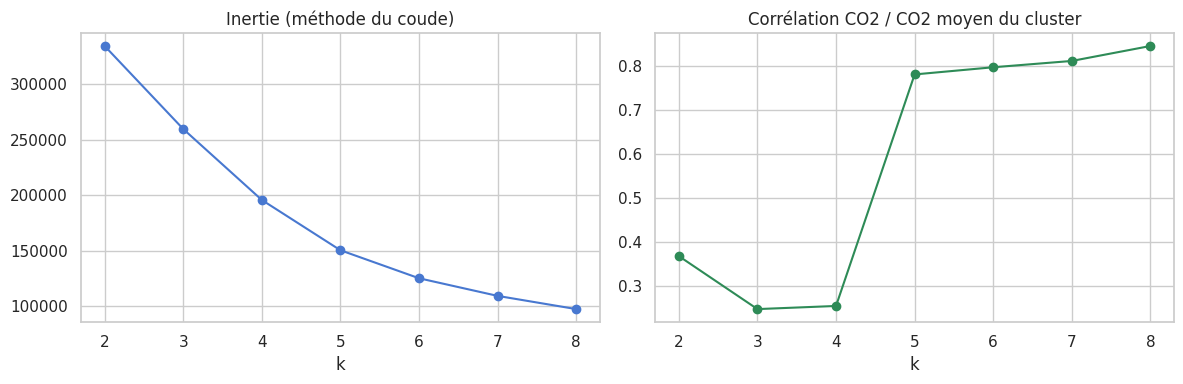

,inertie,corr. CO2 / CO2 moyen du cluster
k,,
2,334460.863,0.367
3,259713.045,0.247
4,195827.664,0.254
5,150574.143,0.781
6,125361.314,0.797
7,109487.816,0.811
8,97608.228,0.845


In [ ]:
# Choix du nombre de clusters k :
#  - inertie de KMeans : on cherche un « coude »
#  - lien avec la cible : corrélation de Pearson entre le CO2 d'une instance et le CO2 moyen de son cluster
co2_tr = train_set["co2_g_km"]
res = []
for k in range(2, 9):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_num)
    co2_moyen_cluster = co2_tr.groupby(km_k.labels_).transform("mean")
    res.append({"k": k, "inertie": km_k.inertia_, "corr. CO2 / CO2 moyen du cluster": co2_tr.corr(co2_moyen_cluster)})
res = pd.DataFrame(res).set_index("k")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(res.index, res["inertie"], marker="o"); ax[0].set_title("Inertie"); ax[0].set_xlabel("k")
ax[1].plot(res.index, res["corr. CO2 / CO2 moyen du cluster"], marker="o", color="seagreen")
ax[1].set_title("Corrélation CO2 / CO2 moyen du cluster"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()
display(res.round(3))


Pour choisir k on regarde deux choses. D'abord l'inertie : elle baisse de moins en moins vite (−45 000 entre 4 et 5, −25 000 entre 5 et 6, −16 000 entre 6 et 7), sans coude très net. Ensuite le lien avec la cible : on calcule la corrélation de Pearson entre le CO2 de chaque instance et le CO2 moyen de son cluster. Elle reste entre 0,25 et 0,37 jusqu'à k = 4, saute à 0,78 pour k = 5, puis monte lentement (0,80 pour k = 6, 0,85 pour k = 8). Attention, ce critère augmente forcément quand k augmente (plus de groupes, donc des moyennes plus fines) et il utilise la cible. On prend donc k = 6, juste après le saut, pour garder peu de groupes faciles à interpréter.


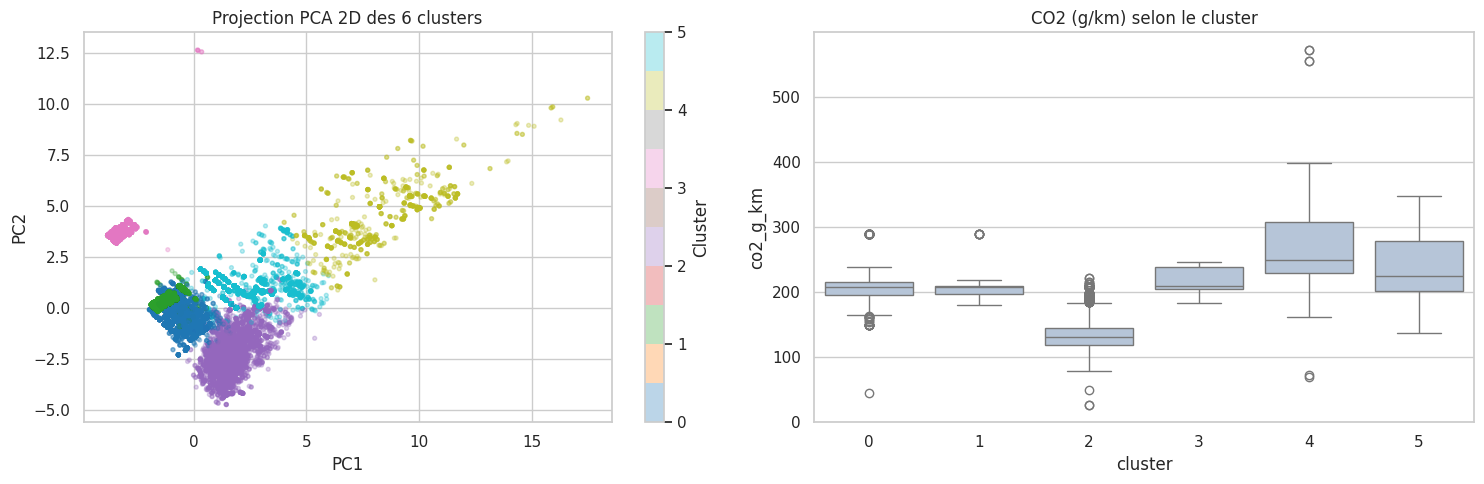

,taille,co2_moyen,masse_moy,puiss_moy,nox_moy,part_gazole,marque_dominante,part_marque_dom
cluster,,,,,,,,
0,19590,207.45,2180.47,105.62,0.22,1.00,MERCEDES,0.96
1,10707,203.80,2109.87,100.61,0.22,1.00,VOLKSWAGEN,0.95
2,4958,132.43,1513.84,107.06,0.09,0.57,MERCEDES,0.41
3,2171,218.57,2585.32,104.18,1.83,0.99,MERCEDES,1.00
4,904,267.63,1958.80,362.57,0.03,0.01,MERCEDES,0.58
5,3866,226.81,2104.93,184.43,0.13,0.55,MERCEDES,0.87


Répartition des classes énergie dans chaque cluster (en % du cluster) :


etiquette_energie,A,B,C,D,E,F,G
cluster,,,,,,,
0,0.0,0.0,0.0,0.1,37.8,62.0,0.2
1,0.0,0.0,0.0,0.0,35.9,64.0,0.1
2,6.2,24.5,38.8,21.8,7.1,1.7,0.0
3,0.0,0.0,0.0,0.0,11.1,88.9,0.0
4,0.2,0.0,0.0,0.0,3.8,47.0,49.0
5,0.0,0.0,1.0,7.8,16.2,46.1,28.8


Corrélation de Pearson entre le CO2 et le CO2 moyen du cluster : 0.797


In [ ]:
K = 6
km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X_num)
explore["cluster"] = km.labels_
X_pca = pca_full.transform(X_num)[:, :2]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sc = ax[0].scatter(X_pca[:, 0], X_pca[:, 1], c=explore["cluster"], cmap="tab10", alpha=0.3, s=8)
ax[0].set_title(f"Projection PCA 2D des {K} clusters"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")
plt.colorbar(sc, ax=ax[0], label="Cluster")
sns.boxplot(x="cluster", y="co2_g_km", data=explore, ax=ax[1], color="lightsteelblue")
ax[1].set_title("CO2 (g/km) selon le cluster"); plt.tight_layout(); plt.show()

# Profil de chaque cluster
profil = explore.groupby("cluster").agg(
    taille=("co2_g_km", "size"), co2_moyen=("co2_g_km", "mean"), masse_moy=("masse_min_kg", "mean"),
    puiss_moy=("puiss_max_kw", "mean"), nox_moy=("nox_g_km", "mean"),
    part_gazole=("carburant", lambda s: (s == "GO").mean()),
    marque_dominante=("marque", lambda s: s.value_counts().index[0]),
    part_marque_dom=("marque", lambda s: s.value_counts(normalize=True).iloc[0])).round(2)
display(profil)

# Lien avec la cible
print("Répartition des classes énergie dans chaque cluster (en % du cluster) :")
display((pd.crosstab(explore["cluster"], explore["etiquette_energie"], normalize="index") * 100).round(1))
r_cluster = explore["co2_g_km"].corr(explore.groupby("cluster")["co2_g_km"].transform("mean"))
print(f"Corrélation de Pearson entre le CO2 et le CO2 moyen du cluster : {r_cluster:.3f}")


Les 6 clusters obtenus (les numéros peuvent changer d'une exécution à l'autre) :
* 19 590 instances : diesels, à 96 % des Mercedes, 106 kW, 2 180 kg, 207 g/km de CO2 en moyenne ;
* 10 707 instances : diesels, à 95 % des Volkswagen, 101 kW, 204 g/km ;
* 2 171 instances : presque uniquement des Mercedes diesel, les plus lourdes (2 585 kg) avec le plus de NOx (1,83 g/km), 219 g/km ;
* 3 866 instances : véhicules puissants (184 kW), 55 % de diesels, 227 g/km ;
* 904 instances : très puissants (363 kW), presque tous à essence, 268 g/km ;
* 4 958 instances : véhicules légers (1 514 kg), 132 g/km. C'est le seul cluster où les classes A à D sont majoritaires (91 % des instances).

K-Means n'a pas utilisé le CO2 pour former les groupes (on s'en est seulement servi pour choisir k), et pourtant le CO2 d'une instance est bien corrélé au CO2 moyen de son cluster (0,80). Par contre le tableau croisé montre que les clusters séparent mal les classes E et F : elles sont présentes dans tous les clusters, et ne sont minoritaires que dans celui des véhicules légers. Les clusters regroupent surtout des types de véhicules (marque, masse, puissance). Ça laisse penser que distinguer E et F sera la partie difficile de la classification.


## 11. Bilan et hypothèses pour la suite

### Bilan de l'exploration
* Il y a 55 003 instances mais seulement 7 435 combinaisons différentes. On découpe donc par description commerciale, et la validation croisée de la section 9 va dans ce sens (RMSE de 10,0 g/km en aléatoire contre 11,24 en groupé).
* Mercedes et Volkswagen font 90,7 % du jeu, surtout des utilitaires diesel. Nos conclusions vaudront surtout pour ce type de véhicules.
* Les cibles sont déséquilibrées : F (55 %) et E (30 %) dominent, et 88,6 % des instances dépassent 160 g/km.
* Les valeurs manquantes dépendent du carburant ; on les impute dans le pipeline avec un indicateur.
* On garde les valeurs extrêmes (supercars, hybrides rechargeables) car ce sont de vrais véhicules.
* On retire `hcnox_g_km`, redondant avec NOx (0,999). Les deux puissances (0,97) et les deux masses (0,78) restent très corrélées.
* On aura deux pipelines : B sans les consommations (le principal) et A avec, comme référence haute.

### Limites qu'on garde en tête
* Le découpage par description laisse encore des versions d'un même modèle des deux côtés (99 % des instances du test).
* On n'a plus de mesure des hydrocarbures pour les essences (HC et HC+NOx retirés).
* Les polluants viennent du même essai que le CO2 ; leur intérêt sera vérifié à l'étape 2.

### Hypothèses pour les étapes suivantes
1. Le CO2 dépend du type de véhicule (voir les clusters), donc une méthode d'ensemble (random forest, boosting, stacking) devrait faire mieux qu'une régression linéaire régularisée, comme dans le dépôt de cknogler. On testera aussi des versions polynomiales de degré 2 de Ridge, Lasso et Elastic Net. On utilisera un `DummyRegressor` comme référence, et pas de régression non régularisée ni d'arbre de décision seul.
2. Comme les deux puissances sont très corrélées (0,97), Ridge devrait donner des coefficients plus stables que Lasso, qui risque d'en garder une seule un peu au hasard.
3. En classification, l'accuracy ne suffira pas (prédire toujours F donne déjà environ 55 %). On comparera les modèles à un `DummyClassifier` avec la précision, le rappel, le F1 et la matrice de confusion.
4. L'écart entre les pipelines A et B mesurera ce qu'apporte la consommation. On s'attend à une erreur beaucoup plus faible avec A.

### Protocole prévu
Validation croisée imbriquée et groupée (`GroupKFold`, même nombre de plis pour tous les modèles), mêmes mesures de performance pour tous les modèles, courbes d'apprentissage, recherche d'hyperparamètres avec graphes en coordonnées parallèles, puis évaluation finale sur le test pour comparer sur-apprentissage et généralisation. Le modèle final sera réentraîné sur tout le train.
